In [1]:
import os, json, sys
import numpy as np
import pandas as pd

sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

VIDEO_LOAD_CONFIG = {
    "type": "video",
    "total_pixels": 16056320,
    "min_pixels": 12544,
    "fps": 1.0,
}

NORMAL_SFT_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_sft_vg_bbox/2026-05-29_22-33-49"
SFT_WITH_FRAME_NUMS_DIR  = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_sft_vg_bbox_frame_nums/2026-06-02_22-18-05"
SFT_DENSE_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_sft_vg_dense_bbox/2026-06-14_17-34-54"
ZS_DIR   = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_zeroshot_vg_bbox/2026-05-24_20-00-11"
ANN_ROOT = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/vstar/uniform_sample_cap_768/2026-05-19_19-14-38"
VIDEO_ROOT = "/projects/torresani-lab/ajay/datasets/V-STaR/videos"

def load_run(run_dir, suffix):
    csv_path = os.path.join(run_dir, "benchmark", "evaluation_results.csv")
    res_path = os.path.join(run_dir, "results.json")
    d = pd.read_csv(csv_path)
    d["score"] = d["score"].astype(int)
    d["correct"] = d["verdict"].astype(str).str.lower().eq("true")
    meta = pd.DataFrame(json.load(open(res_path)))[["qid", "vid", "domain"]]
    d = d.merge(meta, on="qid", how="left")
    return d.rename(columns={
        "generated_answer": f"generated_answer_{suffix}",
        "score": f"score_{suffix}",
        "correct": f"correct_{suffix}",
    })

def load_run_unscored(run_dir, suffix):
    """Load a run's raw outputs (no benchmark CSV yet); returns only the generated answers."""
    raw = pd.DataFrame(json.load(open(os.path.join(run_dir, "results.json"))))
    return raw.rename(columns={"generated_answer": f"generated_answer_{suffix}"})[["qid", f"generated_answer_{suffix}"]]

sft     = load_run(NORMAL_SFT_DIR,        "sft")
sft_fn  = load_run(SFT_WITH_FRAME_NUMS_DIR, "sft_fn")[["qid", "generated_answer_sft_fn", "score_sft_fn", "correct_sft_fn"]]
sft_dense = load_run_unscored(SFT_DENSE_DIR, "sft_dense")  # not benchmarked yet, raw outputs only
zs      = load_run(ZS_DIR,                "zs")[["qid", "generated_answer_zs", "score_zs", "correct_zs"]]

df = sft.merge(sft_fn, on="qid").merge(sft_dense, on="qid").merge(zs, on="qid").reset_index(drop=True)

print(f"{len(df)} samples loaded.")
for suffix, label in [("sft", "SFT"), ("sft_fn", "SFT+FrameNums"), ("zs", "ZeroShot")]:
    print(f"{label} score distribution:"); print(df[f"score_{suffix}"].value_counts().sort_index())

2083 samples loaded.
SFT score distribution:
score_sft
0    164
1    800
2    796
3    323
Name: count, dtype: int64
SFT+FrameNums score distribution:
score_sft_fn
-1      1
 0    177
 1    760
 2    858
 3    287
Name: count, dtype: int64
ZeroShot score distribution:
score_zs
0    141
1    695
2    829
3    418
Name: count, dtype: int64


In [2]:
from qwen_vl_utils import process_vision_info
from src.utils.annotation_utils import load_mask_annotations, annotate_frames
from src.utils.notebook_utils import show_video

def show(idx, fps=1, width=520):
    """Print SFT, SFT+FrameNums, SFT+Dense, and ZeroShot CoTs and render the annotated video for a given index."""
    r = df.iloc[idx]
    print(f"[{idx}] qid={r.qid}  domain={r.domain}")
    print(f"Q : {r.question}")
    print(f"GT: {r.gt_answer}")
    print(f"\n--- SFT (score={r.score_sft}, correct={r.correct_sft}) ---\n{r.generated_answer_sft}")
    print(f"\n--- SFT+FrameNums (score={r.score_sft_fn}, correct={r.correct_sft_fn}) ---\n{r.generated_answer_sft_fn}")
    print(f"\n--- SFT+Dense (not benchmarked) ---\n{r.generated_answer_sft_dense}")
    print(f"\n--- ZeroShot (score={r.score_zs}, correct={r.correct_zs}) ---\n{r.generated_answer_zs}")

    vid_path = os.path.join(VIDEO_ROOT, f"{r.vid}.mp4")
    ann_path = os.path.join(ANN_ROOT, "masks", f"{r.qid}.json")

    if not os.path.exists(vid_path):
        print(f"\n[no video at {vid_path}]"); return
    if not os.path.exists(ann_path):
        print(f"\n[no annotation for {r.qid}]"); return

    messages = [{"content": [{**VIDEO_LOAD_CONFIG, "video": vid_path}]}]
    _, video_inputs = process_vision_info(messages)
    frames = video_inputs[0]

    record = load_mask_annotations(ann_path)
    annotated = annotate_frames(frames, record["masks_np"], annotation_type="bbox", thickness=3)
    annotated = np.stack(annotated)
    print(f"\n[video: {len(annotated)} frames @ {annotated.shape[2]}x{annotated.shape[1]}]")
    return show_video(frames=annotated, fps=fps, width=width)

In [3]:
# Build a pool of indices where a given model got the answer wrong, then step through only those.
def wrong_indices(suffix="sft_fn"):
    """Return df indices where the given model (sft/sft_fn/zs) was judged incorrect."""
    return df.index[~df[f"correct_{suffix}"]].tolist()

def show_wrong(i, suffix="sft_fn", fps=1, width=520):
    """Show the i-th wrong-answer sample for the given model (i indexes into the wrong pool)."""
    pool = wrong_indices(suffix)
    print(f"[wrong {i}/{len(pool)-1}] {suffix} incorrect pool")
    return show(pool[i], fps=fps, width=width)

In [4]:
# Change to any index 0 .. len(df)-1
show(31)

# Or iterate only over samples the model got wrong (i indexes into the wrong pool):
# show_wrong(0, suffix="sft_fn")

[31] qid=5608194207_0  domain=Indoor
Q : who is towards the cup in the room?
GT: an adult in white is towards a cup in a room.

--- SFT (score=2, correct=True) ---
<think>There is a red bounding box around a person who is in the doorway of a room. This person is positioned towards the cup on the table. The person is wearing a dark-colored dress and appears to be facing the table where the cup is placed. Therefore, the person in the red bounding box is the one towards the cup in the room.</think>
<answer>The person in the red bounding box is towards the cup in the room.</answer>

--- SFT+FrameNums (score=0, correct=False) ---
<think>The video begins with a view of a man standing in a dimly lit room, facing away from the camera. The camera then zooms in on the man, and the man turns his head to the right, revealing a woman standing behind him. The woman is wearing a black dress and is positioned close to the man. The camera then zooms out, showing the full view of the room. The man and w

qwen-vl-utils using torchcodec to read video.



[video: 22 frames @ 644x476]


'/tmp/_preview.mp4'

In [5]:
import re

def mentions_red_bbox(text):
    return bool(isinstance(text, str) and re.search(r"red bound|red box|bounding box", text, re.IGNORECASE))

for suffix, label in [("sft", "SFT"), ("sft_fn", "SFT+FrameNums"), ("zs", "ZeroShot")]:
    col = f"generated_answer_{suffix}"
    flag = f"has_red_bbox_{suffix}"
    df[flag] = df[col].map(mentions_red_bbox)
    n = len(df)
    n_with = df[flag].sum()
    print(f"=== {label} ===")
    print(f"Mention red bbox : {n_with}  ({n_with/n:.1%})")
    print(f"No mention       : {n - n_with}  ({(n - n_with)/n:.1%})")
    print("Accuracy split by red bbox mention:")
    print(df.groupby(flag)[f"correct_{suffix}"].agg(["mean", "count"]).rename(columns={"mean": "accuracy"}))
    print()

=== SFT ===
Mention red bbox : 1504  (72.2%)
No mention       : 579  (27.8%)
Accuracy split by red bbox mention:
                  accuracy  count
has_red_bbox_sft                 
False             0.566494    579
True              0.525931   1504

=== SFT+FrameNums ===
Mention red bbox : 492  (23.6%)
No mention       : 1591  (76.4%)
Accuracy split by red bbox mention:
                     accuracy  count
has_red_bbox_sft_fn                 
False                0.538655   1591
True                 0.585366    492

=== ZeroShot ===
Mention red bbox : 105  (5.0%)
No mention       : 1978  (95.0%)
Accuracy split by red bbox mention:
                 accuracy  count
has_red_bbox_zs                 
False            0.598584   1978
True             0.600000    105



Total <frame> tags parsed: 10187
Frame 0: 1338 (13.1%)


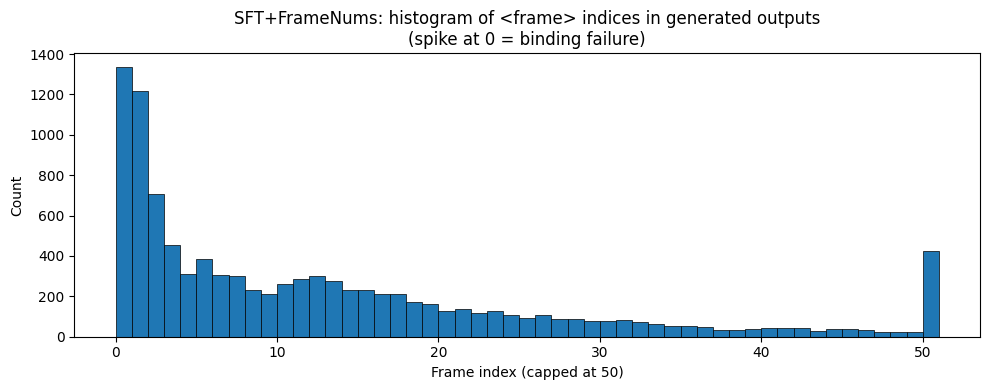

In [5]:
import re
import matplotlib.pyplot as plt

def extract_frame_indices(text):
    if not isinstance(text, str):
        return []
    return [int(m) for m in re.findall(r"<frame>(\d+)</frame>", text)]

all_frames = []
for ans in df["generated_answer_sft_fn"]:
    all_frames.extend(extract_frame_indices(ans))

print(f"Total <frame> tags parsed: {len(all_frames)}")
n_zero = sum(f == 0 for f in all_frames)
print(f"Frame 0: {n_zero} ({n_zero/len(all_frames):.1%})")

capped = [min(f, 50) for f in all_frames]
plt.figure(figsize=(10, 4))
plt.hist(capped, bins=range(0, 52), edgecolor="black", linewidth=0.5)
plt.xlabel("Frame index (capped at 50)")
plt.ylabel("Count")
plt.title("SFT+FrameNums: histogram of <frame> indices in generated outputs\n(spike at 0 = binding failure)")
plt.tight_layout()
plt.show()


In [7]:
def has_loop(text, n=30, k=20):
    """Return True if any n-gram appears at least k times in text."""
    if not isinstance(text, str):
        return False
    words = text.lower().split()
    if len(words) < n:
        return False
    counts = {}
    for i in range(len(words) - n + 1):
        gram = tuple(words[i:i+n])
        counts[gram] = counts.get(gram, 0) + 1
        if counts[gram] >= k:
            return True
    return False

N, K = 5, 3
for suffix, label in [("sft", "SFT"), ("sft_fn", "SFT+FrameNums"), ("zs", "ZeroShot")]:
    col = f"generated_answer_{suffix}"
    looped = df[col].map(lambda t: has_loop(t, n=N, k=K))
    n_loop = looped.sum()
    n_total = len(df)
    print(f"{label}: {n_loop}/{n_total} looping ({n_loop/n_total:.1%})")
    print(f"  Accuracy (looping):     {df.loc[looped, f'correct_{suffix}'].mean():.3f}")
    print(f"  Accuracy (no looping):  {df.loc[~looped, f'correct_{suffix}'].mean():.3f}")


SFT: 553/2083 looping (26.5%)
  Accuracy (looping):     0.528
  Accuracy (no looping):  0.541
SFT+FrameNums: 705/2083 looping (33.8%)
  Accuracy (looping):     0.560
  Accuracy (no looping):  0.544
ZeroShot: 0/2083 looping (0.0%)
  Accuracy (looping):     nan
  Accuracy (no looping):  0.599


## SFT+Dense Checks (unscored)

Runs the notebook's output-level checks on the dense bbox SFT run. This run has no benchmark scores yet, so accuracy splits and score distributions are omitted — only coverage rates (red bbox mentions, looping). The dense run produces no `<frame>` tags, so that check does not apply.

In [8]:
col = "generated_answer_sft_dense"
n = len(df)

# Red bounding box mention rate (reuses mentions_red_bbox defined above).
df["has_red_bbox_sft_dense"] = df[col].map(mentions_red_bbox)
n_with = df["has_red_bbox_sft_dense"].sum()
print("=== SFT+Dense: red bbox mentions ===")
print(f"Mention red bbox : {n_with}  ({n_with/n:.1%})")
print(f"No mention       : {n - n_with}  ({(n - n_with)/n:.1%})")

# Looping / n-gram repetition rate (reuses has_loop defined above).
N, K = 5, 3
looped = df[col].map(lambda t: has_loop(t, n=N, k=K))
n_loop = looped.sum()
print(f"\n=== SFT+Dense: looping (n={N}, k={K}) ===")
print(f"Looping : {n_loop}/{n} ({n_loop/n:.1%})")

=== SFT+Dense: red bbox mentions ===
Mention red bbox : 867  (41.6%)
No mention       : 1216  (58.4%)

=== SFT+Dense: looping (n=5, k=3) ===
Looping : 934/2083 (44.8%)


## SFT+Dense CoT Browser

Step through the dense bbox SFT outputs. The dense run is unscored, so wrong-answer filtering uses a reference run's correctness (`ref_suffix` = sft / sft_fn / zs).

In [9]:
def show_dense(idx, fps=1, width=520):
    """Print SFT+Dense alongside SFT, SFT+FrameNums, and ZeroShot CoTs and render the annotated video."""
    r = df.iloc[idx]

    def section(title, body):
        print(f"\n{'='*70}\n{title}\n{'-'*70}\n{body}")

    print(f"[{idx}] qid={r.qid}   domain={r.domain}")
    print("QUESTION: ", r.question)
    print("GROUND TRUTH: ", r.gt_answer)
    section("SFT+DENSE (not benchmarked)", r.generated_answer_sft_dense)
    section(f"SFT          (score={r.score_sft}, correct={r.correct_sft})", r.generated_answer_sft)
    section(f"SFT+FRAMENUMS (score={r.score_sft_fn}, correct={r.correct_sft_fn})", r.generated_answer_sft_fn)
    section(f"ZEROSHOT     (score={r.score_zs}, correct={r.correct_zs})", r.generated_answer_zs)

    vid_path = os.path.join(VIDEO_ROOT, f"{r.vid}.mp4")
    ann_path = os.path.join(ANN_ROOT, "masks", f"{r.qid}.json")

    if not os.path.exists(vid_path):
        print(f"\n[no video at {vid_path}]"); return
    if not os.path.exists(ann_path):
        print(f"\n[no annotation for {r.qid}]"); return

    messages = [{"content": [{**VIDEO_LOAD_CONFIG, "video": vid_path}]}]
    _, video_inputs = process_vision_info(messages)
    frames = video_inputs[0]

    record = load_mask_annotations(ann_path)
    annotated = annotate_frames(frames, record["masks_np"], annotation_type="bbox", thickness=3)
    annotated = np.stack(annotated)
    print(f"\n[video: {len(annotated)} frames @ {annotated.shape[2]}x{annotated.shape[1]}]")
    return show_video(frames=annotated, fps=fps, width=width)


def show_wrong_dense(i, ref_suffix="zs", fps=1, width=520):
    """Show the i-th sample where the reference run (sft/sft_fn/zs) was judged incorrect."""
    pool = df.index[~df[f"correct_{ref_suffix}"]].tolist()
    print(f"[wrong {i}/{len(pool)-1}] {ref_suffix} incorrect pool")
    return show_dense(pool[i], fps=fps, width=width)

In [19]:
# Change to any index 0 .. len(df)-1
show_dense(2000)

[2000] qid=GOT-10k_Val_000012&bepwr1-CNRU_0   domain=Tutorial
QUESTION:  what walks on the grass?
GROUND TRUTH:  A armadillo walks on the grass.

SFT+DENSE (not benchmarked)
----------------------------------------------------------------------
<think>I see a man in a lab coat standing next to a Tesla Model S in a garage. The video starts with a static screen, then cuts to the garage where the man is holding a microphone, speaking directly to the camera. He gestures towards the car, which is a sleek, black Tesla. The car is shown in detail: it has a modern design with a large screen on the dashboard and a distinctive front grille. The man seems to be explaining something about the car, possibly its features or performance. As he speaks, the camera pans slightly to show more of the car’s interior, highlighting the spacious cabin and comfortable seats. The man continues his presentation, occasionally pointing out specific aspects of the vehicle. The video then transitions to show the car

'/tmp/_preview.mp4'

## ZeroShot + RCap Comparison

Loads the region-caption (rcap) zeroshot run and compares it side-by-side with the standard zeroshot run. No benchmark scores yet for rcap — raw outputs only.

In [21]:
import os, json, sys
import numpy as np
import pandas as pd

sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")

In [22]:
RCAP_ZS_DIR = "/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_zeroshot_rcap_vg/2026-06-11_23-29-21"
RCAP_CAPTIONS_ROOT = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/vstar/vstar_qwen3vl32b_rcap"

# Load rcap results (no benchmark CSV yet; raw outputs only)
rcap_raw = pd.DataFrame(json.load(open(os.path.join(RCAP_ZS_DIR, "results.json"))))
rcap_raw = rcap_raw.rename(columns={"generated_answer": "generated_answer_rcap"})
rcap_cols = rcap_raw[["qid", "generated_answer_rcap"]]

# Merge with existing df on qid (inner join keeps only samples present in both)
df_rcap = df.merge(rcap_cols, on="qid").reset_index(drop=True)

def load_rcap_caption(qid):
    """Load the region caption fed into rcap inference for a given qid."""
    with open(os.path.join(RCAP_CAPTIONS_ROOT, "samples", f"{qid}.json")) as f:
        return json.load(f)["rcap"]

print(f"{len(df_rcap)} samples after merging rcap with existing df.")


2083 samples after merging rcap with existing df.


In [37]:
def show_rcap(idx, fps=1, width=520):
    """Print ZeroShot and RCap ZeroShot outputs and render the annotated video for a given index."""
    r = df_rcap.iloc[idx]

    def section(title, body):
        print(f"\n{'='*70}\n{title}\n{'-'*70}\n{body}")

    print(f"[{idx}] qid={r.qid}   domain={r.domain}")
    print("QUESTION: ", r.question)
    print("GROUND TRUTH: ", r.gt_answer)
    section("REGION CAPTION", load_rcap_caption(r.qid))
    section(f"ZEROSHOT   (score={r.score_zs}, correct={r.correct_zs})", r.generated_answer_zs)
    section("ZEROSHOT + RCAP", r.generated_answer_rcap)

    vid_path = os.path.join(VIDEO_ROOT, f"{r.vid}.mp4")
    ann_path = os.path.join(ANN_ROOT, "masks", f"{r.qid}.json")

    if not os.path.exists(vid_path):
        print(f"\n[no video at {vid_path}]"); return
    if not os.path.exists(ann_path):
        print(f"\n[no annotation for {r.qid}]"); return

    messages = [{"content": [{**VIDEO_LOAD_CONFIG, "video": vid_path}]}]
    _, video_inputs = process_vision_info(messages)
    frames = video_inputs[0]

    record = load_mask_annotations(ann_path)
    annotated = annotate_frames(frames, record["masks_np"], annotation_type="bbox", thickness=3)
    annotated = np.stack(annotated)
    # uniformly sample 16 frames
    indices = np.linspace(0, len(annotated) - 1, 16, dtype=int)
    annotated = annotated[indices]
    return show_video(frames=annotated, fps=fps, width=width)


def wrong_indices_rcap(ref_suffix="zs"):
    """Return df_rcap indices where the reference model (zs/sft/sft_fn) was judged incorrect."""
    return df_rcap.index[~df_rcap[f"correct_{ref_suffix}"]].tolist()


def show_wrong_rcap(i, ref_suffix="zs", fps=1, width=520):
    """Show the i-th wrong-answer sample (for ref_suffix) in the rcap df."""
    pool = wrong_indices_rcap(ref_suffix)
    print(f"[wrong {i}/{len(pool)-1}] {ref_suffix} incorrect pool (rcap df)")
    return show_rcap(pool[i], fps=fps, width=width)


In [83]:
# Change to any index 0 .. len(df_rcap)-1
idx = 60
show_rcap(idx,fps=4)

# Or iterate only over samples zeroshot got wrong:
# show_wrong_rcap(0, ref_suffix="zs")

[60] qid=6592821115_0   domain=Life
QUESTION:  who is in front of the adult with long hair?
GROUND TRUTH:  A baby in white is in front of an adult with long hair.

REGION CAPTION
----------------------------------------------------------------------
<caption>The red bounding box highlights a toddler wearing white pajamas with colorful polka dots and a bear design on the front. The child is standing in front of an adult woman with long dark hair, who is sitting on the floor. The toddler moves slightly, turning and shifting position while being gently supported by the adult’s hands. At times, the toddler faces forward, smiling, and appears to be interacting playfully with the adult. The adult smiles warmly and engages with the child, occasionally lifting or adjusting the toddler’s position. In the background, other children are visible, including one in red pants and another in a striped shirt, but they remain out of focus. The setting appears to be a cozy, wood-paneled living room with 

'/tmp/_preview.mp4'

## Synthetic CoT Answer-Check Summary

Parses the per-sample JSON files produced by `src/dataset/openo3/str_cot_synth.py` and reports how many passed the heuristic answer check, and for the failures, the breakdown of reasons.

In [1]:
import glob
import os, json
from collections import Counter

STR_COT_SAMPLES_ROOT = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/openo3video/openo3_str_cot_synth_no_gt_ans_mod/samples"

# Load every sample (keep the full record so we can browse failures below).
cot_samples = []
for path in glob.glob(os.path.join(STR_COT_SAMPLES_ROOT, "*.json")):
    with open(path) as f:
        cot_samples.append(json.load(f))

n = len(cot_samples)
n_passed = sum(s["answer_check"]["passed"] for s in cot_samples)
print(f"{n} samples parsed.")
print(f"Passed: {n_passed} ({n_passed/n:.1%})")
print(f"Failed: {n - n_passed} ({(n - n_passed)/n:.1%})")

# Reason breakdown for the failures.
fail_reasons = Counter(s["answer_check"]["reason"] for s in cot_samples if not s["answer_check"]["passed"])
print("\nFailure reasons:")
for reason, count in fail_reasons.most_common():
    print(f"  {reason:15s} {count:5d}  ({count/n:.1%})")


def failed_by_reason(reason):
    """Return all sample records whose answer_check failed with the given reason."""
    return [s for s in cot_samples if not s["answer_check"]["passed"] and s["answer_check"]["reason"] == reason]


def show_cot(s):
    """Print the question, GT answer, answer_check, and the generated CoT for a sample."""
    print(f"id={s['id']}  check={s['answer_check']}")
    print(f"Q : {s['question']}")
    print(f"GT: {s['gt_answer']}")
    print(f"\n--- CoT ---\n{s['cot']}")


def make_iterator(reason):
    """Build a stepper over the failures for a given reason. Call the returned fn with an index."""
    pool = failed_by_reason(reason)
    def step(i):
        print(f"[{reason} {i}/{len(pool)-1}]  ({len(pool)} total)")
        show_cot(pool[i])
    return step


6758 samples parsed.
Passed: 4612 (68.2%)
Failed: 2146 (31.8%)

Failure reasons:
  low_overlap      2130  (31.5%)
  no_answer_tag      16  (0.2%)


In [3]:
# Failures: low_overlap — answer extracted but token overlap with GT below the floor.
low_overlap = make_iterator("low_overlap")
low_overlap(4)

# Create a simple CoT verification script that does the following: 
# 1. For those CoTs with low overlap, load a lighweight model, suggest me some good ones for this task, using vLLM, and in one pass, get a binary sc

[low_overlap 4/2129]  (2130 total)
id=000012  check={'passed': False, 'reason': 'low_overlap', 'overlap': 0.167}
Q : What is used to clean the knife after the dirty paper towel is thrown away?
GT: A clean paper towel from a roll is used to wipe the knife clean.

--- CoT ---
I see the red bounding box highlighting the person in the black chef's jacket. They are actively sharpening a knife on a whetstone, moving it back and forth with controlled motions. Their focus is intense, and they occasionally pause to inspect the blade or adjust their grip. Around them, there are various kitchen tools and ingredients on the white table — other knives, bowls, and a crumpled paper towel lying nearby, which suggests it was used earlier. After finishing the sharpening process, they pick up the knife and begin wiping it with a clean section of paper towel.

Now, I notice another red bounding box pointing to the paper towel roll on the left side of the table. It’s stationary throughout, with its white s

In [4]:
# Failures: no_answer_tag — no <answer>...</answer> span found in the CoT.
no_answer_tag = make_iterator("no_answer_tag")
no_answer_tag(0)

[no_answer_tag 0/15]  (16 total)
id=001077  check={'passed': False, 'reason': 'no_answer_tag', 'overlap': 0.0}
Q : What is the person using to water the tree?
GT: The person is using a gray watering can with a long spout to water the newly planted tree.

--- CoT ---
I need to figure out what the person is using to water the tree. Let me think step by step.

First, I notice that in one part of the video, there's a red bounding box highlighting a **watering can**. The region shows a blue watering can with a long spout, being held in someone’s hand as they pour water onto the soil around the base of a newly planted tree. The can is tilted, and water is flowing steadily into the soil. The person is wearing brown boots and standing on grass near the tree, which is surrounded by mulch. This suggests the watering can is actively being used for watering.

Then, I see another red bounding box highlighting the **person**. In this view, the person is holding a hose with a spray nozzle, and water 

In [5]:
# Failures: empty_answer — <answer> tag present but contained no word tokens.
empty_answer = make_iterator("empty_answer")
empty_answer(0)

[empty_answer 0/-1]  (0 total)


IndexError: list index out of range

In [6]:
# Correct samples — answer_check passed.
passed_samples = [s for s in cot_samples if s["answer_check"]["passed"]]

def correct(i):
    print(f"[correct {i}/{len(passed_samples)-1}]  ({len(passed_samples)} total)")
    show_cot(passed_samples[i])

correct(2)

[correct 2/4611]  (4612 total)
id=000004  check={'passed': True, 'reason': 'ok', 'overlap': 0.55}
Q : What is drawn on the floor of the deck for the game being played?
GT: A large triangle with white lines is drawn on the floor. It is a scoring area for a shuffleboard game, with sections marked with numbers.

--- CoT ---
I see the red bounding box highlighting a person standing on the wooden deck of what appears to be a ship. The person is wearing dark clothing and white shoes, positioned near the railing, and remains mostly stationary as the camera moves. They seem to be observing or participating in a game. As I track this person across frames, I notice they are near a playing area marked with white lines and numbers on the floor.

Looking more closely at the deck surface, especially when the camera pans over it, I can clearly see a large triangular grid drawn in white paint. This grid is divided into several sections, each labeled with numbers such as 10, 8, 7, and "10 OFF." There a

Correct samples: 4612
Total mentions: 6094
With >=1 mention: 4591 (99.5%)


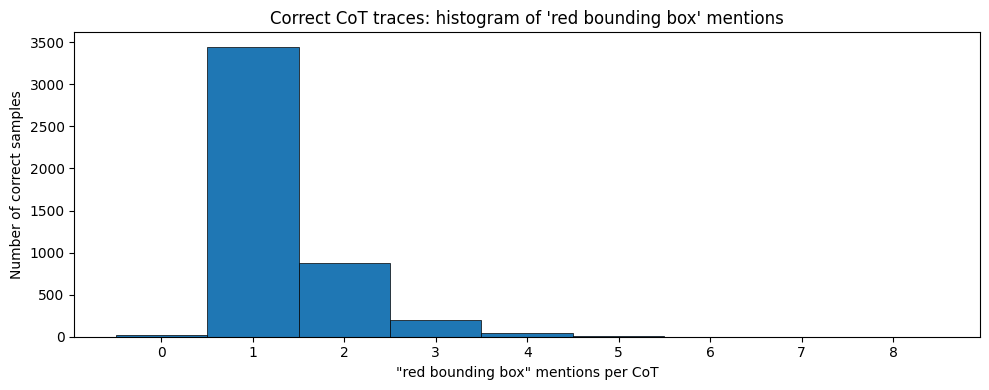

In [7]:
# Histogram: number of "red bounding box" mentions per CoT trace (correct samples only).
import matplotlib.pyplot as plt

counts = [s["cot"].lower().count("red bounding box") for s in passed_samples]

print(f"Correct samples: {len(counts)}")
print(f"Total mentions: {sum(counts)}")
print(f"With >=1 mention: {sum(c > 0 for c in counts)} ({sum(c > 0 for c in counts)/len(counts):.1%})")

max_c = max(counts)
plt.figure(figsize=(10, 4))
plt.hist(counts, bins=range(0, max_c + 2), align="left", edgecolor="black", linewidth=0.5)
plt.xlabel('"red bounding box" mentions per CoT')
plt.ylabel("Number of correct samples")
plt.title("Correct CoT traces: histogram of 'red bounding box' mentions")
plt.xticks(range(0, max_c + 1))
plt.tight_layout()
plt.show()

In [14]:
# Dropped samples — entries removed by the verify/refine pass (dropped.json), grouped by reason.
DROPPED_JSON = os.path.join(os.path.dirname(STR_COT_SAMPLES_ROOT), "dropped.json")

dropped = json.load(open(DROPPED_JSON))
print(f"{len(dropped)} dropped samples.")
print("\nReasons:")
for reason, count in Counter(d["reason"] for d in dropped).most_common():
    print(f"  {reason:15s} {count:5d}  ({count/len(dropped):.1%})")


def dropped_by_reason(reason):
    """Return dropped entries with the given reason."""
    return [d for d in dropped if d["reason"] == reason]


def make_dropped_iterator(reason):
    """Build a stepper over dropped samples for a given reason; loads each sample's full record from disk."""
    pool = dropped_by_reason(reason)
    def step(i):
        d = pool[i]
        print(f"[{reason} {i}/{len(pool)-1}]  ({len(pool)} total)")
        show_cot(json.load(open(d["path"])))
    return step


1320 dropped samples.

Reasons:
  judged_0         1312  (99.4%)
  no_answer_tag       8  (0.6%)


In [16]:
# Step through samples dropped by the judge (judged_0). Change reason to "no_answer_tag" for the other bucket.
judged_0 = make_dropped_iterator("judged_0")
judged_0(1)

[judged_0 1/1311]  (1312 total)
id=000018  check={'passed': False, 'reason': 'low_overlap', 'overlap': 0.261}
Q : Who is the person the lady model is touching?
GT: The lady model is touching a shirtless man with dark hair. He is posing with her in a bathroom setting after having just shaved his face.

--- CoT ---
I see the red bounding box highlighting the man at the start of the video. He’s shirtless, with dark, neatly styled hair, and is applying shaving cream to his face with his hand. Then he uses a Gillette razor to shave. The setting is clearly a bathroom with blue tiled walls — this gives me context for the environment.

As the video progresses, I notice the same man continues shaving, and there’s a split-screen comparison showing shaving with foam versus Gillette Series Gel. This reinforces that the man is the central figure throughout the video, and all actions are focused on him.

Then, later in the sequence, the red bounding box now includes both the man and a woman standing

## Synthetic CoT Looping

Detect n-gram looping in the synthetic CoT traces (`cot_samples`), report statistics, and step through the looped traces.

In [ ]:
# Looping statistics over the synthetic CoT traces (reuses has_loop defined above).
N, K = 5, 3
looped_samples = [s for s in cot_samples if has_loop(s["cot"], n=N, k=K)]

n = len(cot_samples)
n_loop = len(looped_samples)
print(f"Looping (n={N}, k={K}): {n_loop}/{n} ({n_loop/n:.1%})")

# Pass rate split by looping.
n_loop_pass = sum(s["answer_check"]["passed"] for s in looped_samples)
n_clean = n - n_loop
n_clean_pass = sum(s["answer_check"]["passed"] for s in cot_samples) - n_loop_pass
print(f"  Pass rate (looping):     {n_loop_pass}/{n_loop} ({n_loop_pass/n_loop:.1%})")
print(f"  Pass rate (no looping):  {n_clean_pass}/{n_clean} ({n_clean_pass/n_clean:.1%})")

In [ ]:
# Step through the looped CoT traces (reuses show_cot defined above).
def show_looped(i):
    print(f"[looped {i}/{len(looped_samples)-1}]  ({len(looped_samples)} total)")
    show_cot(looped_samples[i])

show_looped(0)